# smFRET — Synthetic vs Experimental Trajectories

Generate a synthetic dataset from a simulator config and compare per-trajectory
statistics against an experimental dataset. The simulator and the experimental
HDF5 files share the same per-photon event format — `(interphoton_times_ms, channels)` —
so a single observable-extractor function works on both.

In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
from pathlib import Path

import numpy as np
import h5py
import torch
import matplotlib.pyplot as plt
from omegaconf import OmegaConf

project_root = Path.cwd().resolve().parent if Path.cwd().name == "analysis" else Path.cwd().resolve()
src_dir = project_root / "src"
if str(src_dir) not in sys.path:
    sys.path.append(str(src_dir))

from simulator import smFRET_simulator_wrapper_from_config, binding_simulator_wrapper_from_config
from priors import generate_fret_prior_from_config

/home/dingeldein/Venvs/fret_sbi/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ─── User configuration ─────────────────────────────────────────────
CONFIG_PATH    = project_root / "conf" / "simulator" / "test_0.yaml"
EXP_DATA_ROOT  = Path("/home/dingeldein/Desktop/fret_sbi/data_ben_schuler/Sturzenegger_transition_path_data")
EXP_CONDITION  = "ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi"
N_SIM_TRAJS    = 1000
N_WORKERS      = max(1, (os.cpu_count() or 2) - 1)
BIN_WIDTH_MS   = 0.25   # for binned-FRET analysis & example plots

config = OmegaConf.load(CONFIG_PATH)
mode = str(config.simulator.get("mode", "equilibrium")).lower()
n_max_photons = int(config.simulator.N_max_photons)
print(f"Config:        {Path(CONFIG_PATH).name}")
print(f"Mode:          {mode}")
print(f"N_max_photons: {n_max_photons}")
print(f"Workers:       {N_WORKERS}")

Config:        test_0.yaml
Mode:          binding
N_max_photons: 5000
Workers:       23


## Shared helpers — common event format

Experimental and synthetic trajectories are both reduced to `(ipt_ms, channels)`
tuples (interphoton times in ms, channel labels with `0=donor`, `1=acceptor`).
Every observable below works on this format, regardless of source.

In [3]:
ACCEPTOR_ID = 1   # detector ID for acceptor in experimental HDF5
DONOR_ID    = 2   # detector ID for donor    in experimental HDF5


def load_experimental_events(traj_file):
    """Load one experimental trajectory as (ipt_ms, channels)."""
    with h5py.File(traj_file, "r") as f:
        detector = f["Detectors"][:]
        ipt_ds   = f["InterPhotonTimes"]
        ipt_raw  = ipt_ds[:]
        macro_ps = int(ipt_ds.attrs["MacroTimeUnitInPicoSeconds"])
    # macrotime units × ps/unit × 1e-9 ps/ms = ms
    ipt_ms   = (ipt_raw.astype(np.int64) * macro_ps * 1e-9).astype(np.float32)
    channels = (detector == ACCEPTOR_ID).astype(np.uint8)
    return ipt_ms, channels


def compute_observables(ipt, channels):
    """Per-trajectory observables from per-photon events."""
    duration_ms = float(ipt.sum())
    n_donor     = int((channels == 0).sum())
    n_acceptor  = int((channels == 1).sum())
    n_total     = n_donor + n_acceptor
    if duration_ms <= 0.0 or n_total == 0:
        return None
    return dict(
        duration_ms   = duration_ms,
        n_donor       = n_donor,
        n_acceptor    = n_acceptor,
        n_total       = n_total,
        donor_rate    = n_donor    / duration_ms,
        acceptor_rate = n_acceptor / duration_ms,
        total_rate    = n_total    / duration_ms,
        fret_eff      = n_acceptor / n_total,
    )


def binned_fret_efficiencies(ipt, channels, bin_width_ms):
    """Time-binned FRET efficiencies along one trajectory (drops empty bins)."""
    if ipt.size == 0:
        return np.empty(0, dtype=np.float32)
    t_arrivals = np.cumsum(ipt.astype(np.float64))
    duration   = float(t_arrivals[-1])
    n_bins     = max(1, int(np.ceil(duration / bin_width_ms)))
    edges      = np.linspace(0.0, n_bins * bin_width_ms, n_bins + 1)
    d, _ = np.histogram(t_arrivals[channels == 0], bins=edges)
    a, _ = np.histogram(t_arrivals[channels == 1], bins=edges)
    total = d + a
    valid = total > 0
    if not valid.any():
        return np.empty(0, dtype=np.float32)
    return (a[valid] / total[valid]).astype(np.float32)


def bin_to_counts(ipt, channels, bin_width_ms):
    """Bin events into a [n_bins, 2] (donor, acceptor) count array for plotting."""
    if ipt.size == 0:
        return np.zeros((1, 2), dtype=np.float32)
    t_arrivals = np.cumsum(ipt.astype(np.float64))
    duration   = float(t_arrivals[-1])
    n_bins     = max(1, int(np.ceil(duration / bin_width_ms)))
    edges      = np.linspace(0.0, n_bins * bin_width_ms, n_bins + 1)
    d, _ = np.histogram(t_arrivals[channels == 0], bins=edges)
    a, _ = np.histogram(t_arrivals[channels == 1], bins=edges)
    return np.stack([d, a], axis=1).astype(np.float32)

## 1. Generate synthetic dataset (N = `N_SIM_TRAJS` transitions)

In [4]:
prior = generate_fret_prior_from_config(config, device="cpu")
if mode == "binding":
    simulator = binding_simulator_wrapper_from_config(config)
else:
    simulator = smFRET_simulator_wrapper_from_config(config)

print(f"Prior dim: {prior.sample((1,)).shape[1]}")

Prior dim: 16


## 1b. Preview prior free-energy landscapes

The simulator config has `num_knots` movable knots inside `[x_min, x_max]`.
The actual spline domain is extended on each side by `num_boundary_knots`
boundary knots (linear pads under `boundary_condition`), so the free-energy
landscape is defined and the integrator can sample well beyond `[x_min, x_max]`.

We sample `N_LANDSCAPES` parameter vectors from the prior and integrate
$U(x) = -\int F(s)\,ds$ from the force spline. The plot spans the **full**
spline domain `[x_knots[0], x_knots[-1]]`; dashed verticals mark the
movable-knot inner region `[x_min, x_max]`.

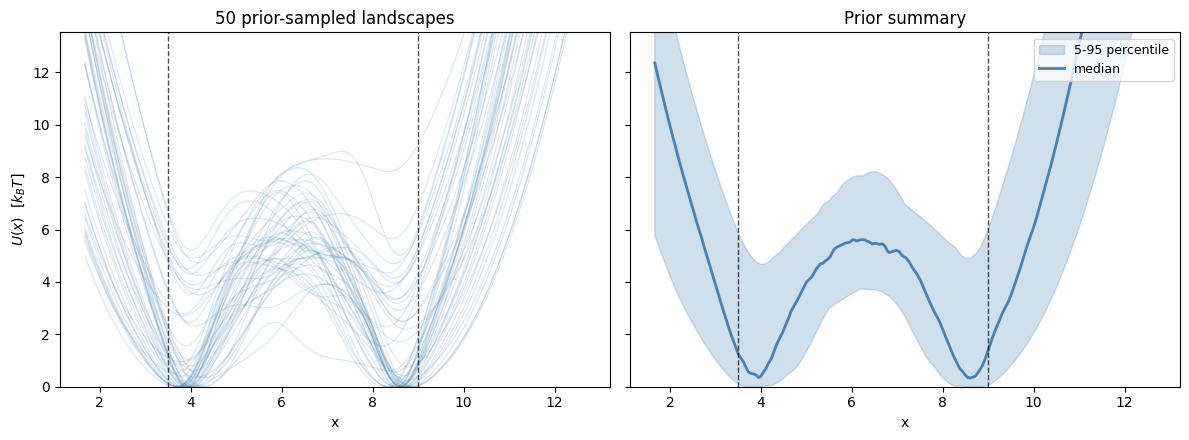

Inner movable-knot range: [3.50, 9.00]
Full spline domain:       [-5.67, 18.17]   (extended by 10 boundary knots on each side)
Y-axis capped at 13.5 kBT (99th percentile of interior U + 5)


In [8]:
# Build prior landscapes for visualisation. Uses the same make_spline_knots /
# GSL integrate_spline path the simulator uses, so what you see here is the
# exact U(x) the integrator runs on.

from utils import make_spline_knots, _validate_bc
from gsl_spline import integrate_spline

N_LANDSCAPES = 50

bc = _validate_bc(config.simulator.boundary_condition)
x_min = float(config.simulator.x_min)
x_max = float(config.simulator.x_max)
num_knots = int(config.prior.num_knots)
max_force = float(config.simulator.max_force)
num_boundary_knots = int(config.simulator.num_boundary_knots)
spline_type = str(config.simulator.spline_type)

# Sample N parameter vectors. Each gives one (x_knots, y_knots) and one U(x).
samples = prior.sample((N_LANDSCAPES,)).cpu().numpy()
curves = []
for theta in samples:
    x_knots, y_knots = make_spline_knots(
        params=theta,
        x_min=x_min, x_max=x_max,
        num_knots=num_knots, max_force=max_force,
        boundary_condition=bc, num_boundary_knots=num_boundary_knots,
    )
    x_grid = np.linspace(float(x_knots[9-1]), float(x_knots[-8+1]), 600)
    U = -integrate_spline(np.asarray(x_knots, dtype=np.float64),
                          np.asarray(y_knots, dtype=np.float64),
                          x_grid, spline_type)
    U = U - U.min()
    curves.append((x_grid, U))

# Stack curves on a common grid (all priors share x_min/x_max so the grid
# is identical across draws).
U_stack = np.stack([c[1] for c in curves], axis=0)
x_common = curves[0][0]
U_median = np.median(U_stack, axis=0)
U_lo, U_hi = np.percentile(U_stack, [5, 95], axis=0)

# Boundary pads drive U up to ~100 kBT at the spline edge (linear-force wall
# integrates to a large value); cap the y-axis at ~p95 of the *interior* U
# values so the inner-region landscape detail isn't squashed.
interior_mask = (x_common >= x_min) & (x_common <= x_max)
y_cap = float(np.percentile(U_stack[:, interior_mask], 99)) + 5.0

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

# Left: spaghetti plot of all sampled landscapes.
for x, U in curves:
    ax1.plot(x, U, color="steelblue", alpha=0.18, lw=0.9)
ax1.axvline(x_min, ls="--", color="black", lw=1.0, alpha=0.7)
ax1.axvline(x_max, ls="--", color="black", lw=1.0, alpha=0.7)
ax1.set_xlabel("x")
ax1.set_ylabel(r"$U(x)$  [$k_B T$]")
ax1.set_title(f"{N_LANDSCAPES} prior-sampled landscapes")
ax1.set_ylim(0, y_cap)

# Right: median + 5-95 percentile band.
ax2.fill_between(x_common, U_lo, U_hi, color="steelblue", alpha=0.25,
                 label="5-95 percentile")
ax2.plot(x_common, U_median, color="steelblue", lw=2.0, label="median")
ax2.axvline(x_min, ls="--", color="black", lw=1.0, alpha=0.7)
ax2.axvline(x_max, ls="--", color="black", lw=1.0, alpha=0.7)
ax2.set_xlabel("x")
ax2.set_ylim(0, y_cap)
ax2.set_title(f"Prior summary")
ax2.legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.show()

print(f"Inner movable-knot range: [{x_min:.2f}, {x_max:.2f}]")
print(f"Full spline domain:       [{float(x_knots[0]):.2f}, {float(x_knots[-1]):.2f}]"
      f"   (extended by {num_boundary_knots} boundary knots on each side)")
print(f"Y-axis capped at {y_cap:.1f} kBT (99th percentile of interior U + 5)")


In [9]:
import multiprocessing as mp
from tqdm.auto import tqdm


def _init_worker():
    seed = (os.getpid() + int.from_bytes(os.urandom(2), "little")) % (2**32 - 1)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(1)


def _generate_one(_unused):
    """Sample theta, simulate, retry on None. Returns (ipt_ms, channels) or None."""
    for _ in range(20):
        theta = prior.sample((1,)).squeeze(0)
        result = simulator(theta)
        if result is None:
            continue
        ipt, chans, length = result
        length = int(length)
        if length <= 0:
            continue
        ipt_np = (ipt.numpy() if hasattr(ipt, "numpy") else ipt)[:length].astype(np.float32)
        ch_np  = (chans.numpy() if hasattr(chans, "numpy") else chans)[:length].astype(np.uint8)
        return ipt_np, ch_np
    return None


sim_events = []
n_failed = 0
ctx = mp.get_context("fork")
with ctx.Pool(processes=N_WORKERS, initializer=_init_worker) as pool:
    pbar = tqdm(total=N_SIM_TRAJS, desc="Sim transitions")
    # Submit generously; we stop pulling as soon as we have enough successes.
    for result in pool.imap_unordered(_generate_one, range(int(N_SIM_TRAJS * 3))):
        if result is None:
            n_failed += 1
            continue
        sim_events.append(result)
        pbar.update(1)
        if len(sim_events) >= N_SIM_TRAJS:
            break
    pbar.close()

sim_events = sim_events[:N_SIM_TRAJS]
print(f"Generated {len(sim_events)} synthetic trajectories  (rejected {n_failed})")

Sim transitions: 100%|██████████| 1000/1000 [00:10<00:00, 96.65it/s]


Generated 1000 synthetic trajectories  (rejected 0)


## 2. Load experimental dataset

In [10]:
exp_dir = EXP_DATA_ROOT / EXP_CONDITION
exp_files = sorted(exp_dir.glob("*.h5"))
print(f"Condition: {EXP_CONDITION}")
print(f"Found {len(exp_files)} experimental HDF5 files")

exp_events = []
for f in exp_files:
    try:
        ipt, chans = load_experimental_events(f)
    except (OSError, KeyError) as e:
        print(f"  [skip] {f.name}: {e}")
        continue
    if ipt.size > 0:
        exp_events.append((ipt, chans))

print(f"Loaded {len(exp_events)} experimental trajectories")

Condition: ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi
Found 591 experimental HDF5 files
Loaded 591 experimental trajectories


## 3. Compute observables

Same function applied to both datasets.

In [11]:
def stats_table(events):
    rows = [r for r in (compute_observables(ipt, ch) for ipt, ch in events) if r is not None]
    return {k: np.array([r[k] for r in rows], dtype=float) for k in rows[0].keys()}


sim_stats = stats_table(sim_events)
exp_stats = stats_table(exp_events)

sim_E_binned = np.concatenate([binned_fret_efficiencies(ipt, ch, BIN_WIDTH_MS) for ipt, ch in sim_events])
exp_E_binned = np.concatenate([binned_fret_efficiencies(ipt, ch, BIN_WIDTH_MS) for ipt, ch in exp_events])

print(f"  sim N={len(sim_events):4d}  median duration={np.median(sim_stats['duration_ms']):6.2f} ms   median E={np.median(sim_stats['fret_eff']):.3f}")
print(f"  exp N={len(exp_events):4d}  median duration={np.median(exp_stats['duration_ms']):6.2f} ms   median E={np.median(exp_stats['fret_eff']):.3f}")

  sim N=1000  median duration=  4.18 ms   median E=0.514
  exp N= 591  median duration=  6.43 ms   median E=0.567


## 4. Distribution overlays — sim vs experiment

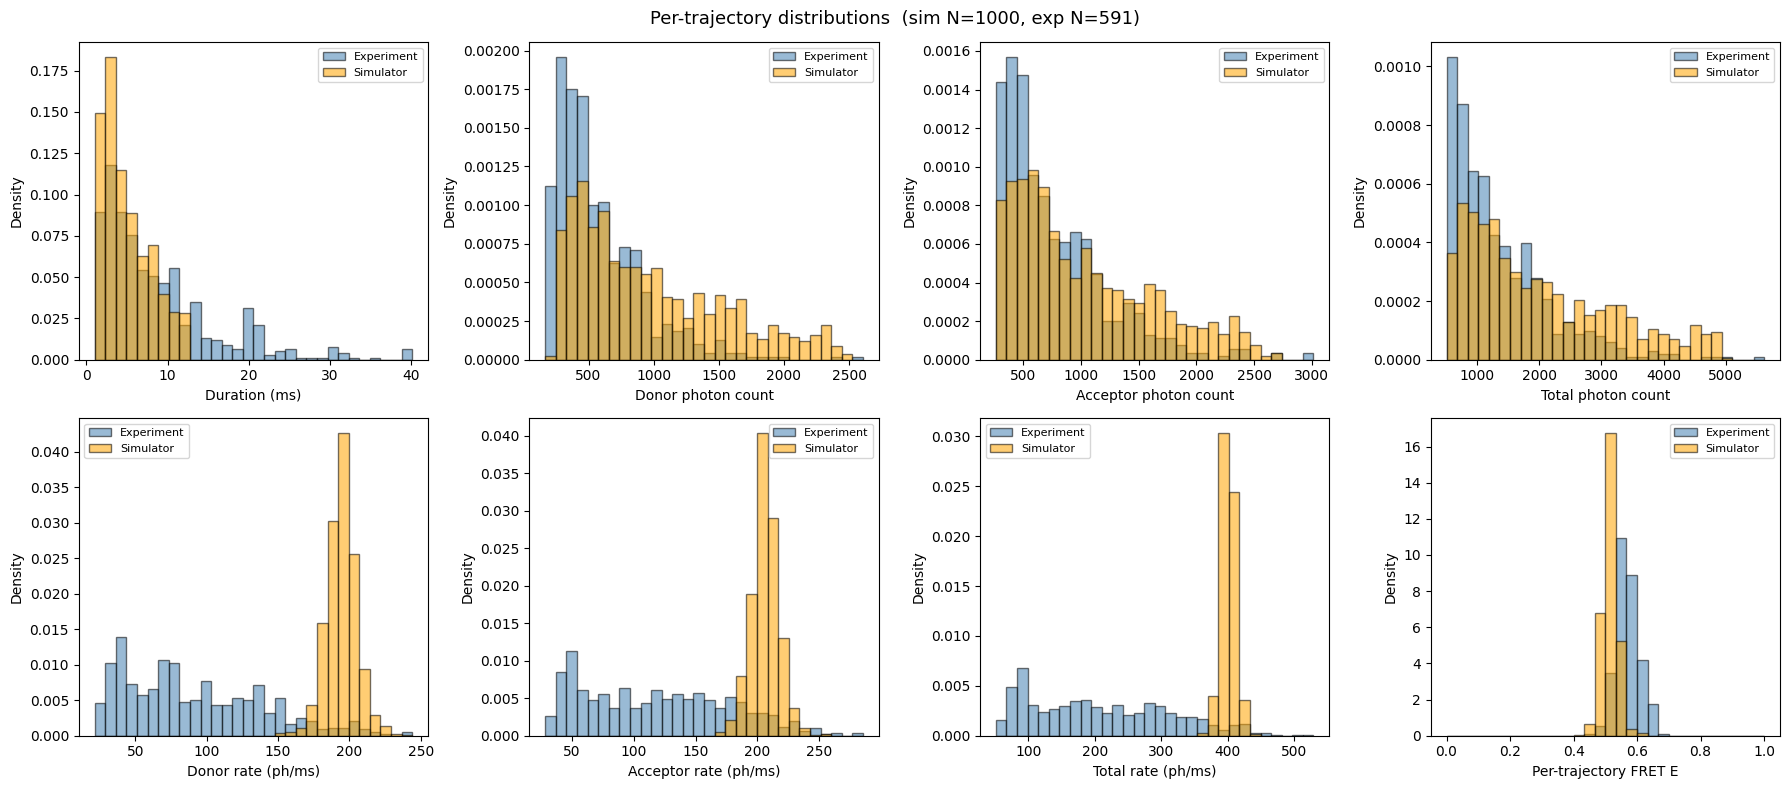

In [12]:
def overlay_hist(ax, sim, exp, label, bins=30, xlim=None, log=False):
    if xlim is None:
        lo = min(float(np.min(sim)), float(np.min(exp)))
        hi = max(float(np.max(sim)), float(np.max(exp)))
    else:
        lo, hi = xlim
    if log:
        lo_pos = max(lo, 1e-3)
        edges = np.geomspace(lo_pos, max(hi, lo_pos * 10), bins + 1)
        ax.set_xscale("log")
    else:
        edges = np.linspace(lo, hi, bins + 1)
    ax.hist(exp, bins=edges, alpha=0.55, color="steelblue", density=True, edgecolor="black", label="Experiment")
    ax.hist(sim, bins=edges, alpha=0.55, color="orange",    density=True, edgecolor="black", label="Simulator")
    ax.set_xlabel(label)
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)


fig, axes = plt.subplots(2, 4, figsize=(18, 8))
overlay_hist(axes[0, 0], sim_stats["duration_ms"],   exp_stats["duration_ms"],   "Duration (ms)")
overlay_hist(axes[0, 1], sim_stats["n_donor"],       exp_stats["n_donor"],       "Donor photon count")
overlay_hist(axes[0, 2], sim_stats["n_acceptor"],    exp_stats["n_acceptor"],    "Acceptor photon count")
overlay_hist(axes[0, 3], sim_stats["n_total"],       exp_stats["n_total"],       "Total photon count")
overlay_hist(axes[1, 0], sim_stats["donor_rate"],    exp_stats["donor_rate"],    "Donor rate (ph/ms)")
overlay_hist(axes[1, 1], sim_stats["acceptor_rate"], exp_stats["acceptor_rate"], "Acceptor rate (ph/ms)")
overlay_hist(axes[1, 2], sim_stats["total_rate"],    exp_stats["total_rate"],    "Total rate (ph/ms)")
overlay_hist(axes[1, 3], sim_stats["fret_eff"],      exp_stats["fret_eff"],      "Per-trajectory FRET E", xlim=(0, 1))
plt.suptitle(f"Per-trajectory distributions  (sim N={len(sim_events)}, exp N={len(exp_events)})", fontsize=13)
plt.tight_layout()
plt.show()

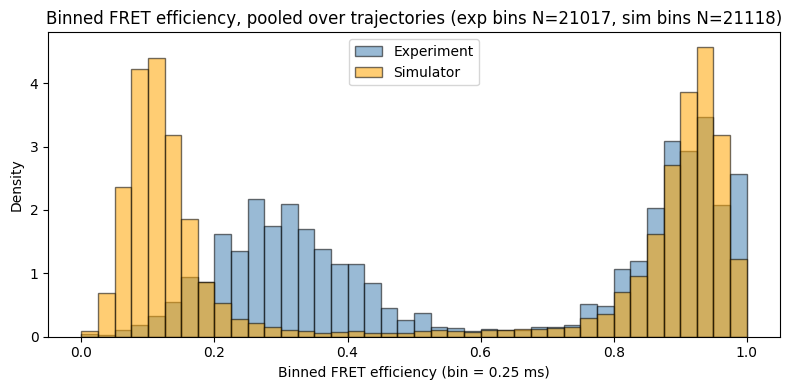

In [70]:
fig, ax = plt.subplots(figsize=(8, 4))
edges = np.linspace(0, 1, 41)
ax.hist(exp_E_binned, bins=edges, alpha=0.55, color="steelblue", density=True, edgecolor="black", label="Experiment")
ax.hist(sim_E_binned, bins=edges, alpha=0.55, color="orange",    density=True, edgecolor="black", label="Simulator")
ax.set_xlabel(f"Binned FRET efficiency (bin = {BIN_WIDTH_MS} ms)")
ax.set_ylabel("Density")
ax.set_title(f"Binned FRET efficiency, pooled over trajectories (exp bins N={len(exp_E_binned)}, sim bins N={len(sim_E_binned)})")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Example trajectories — side by side

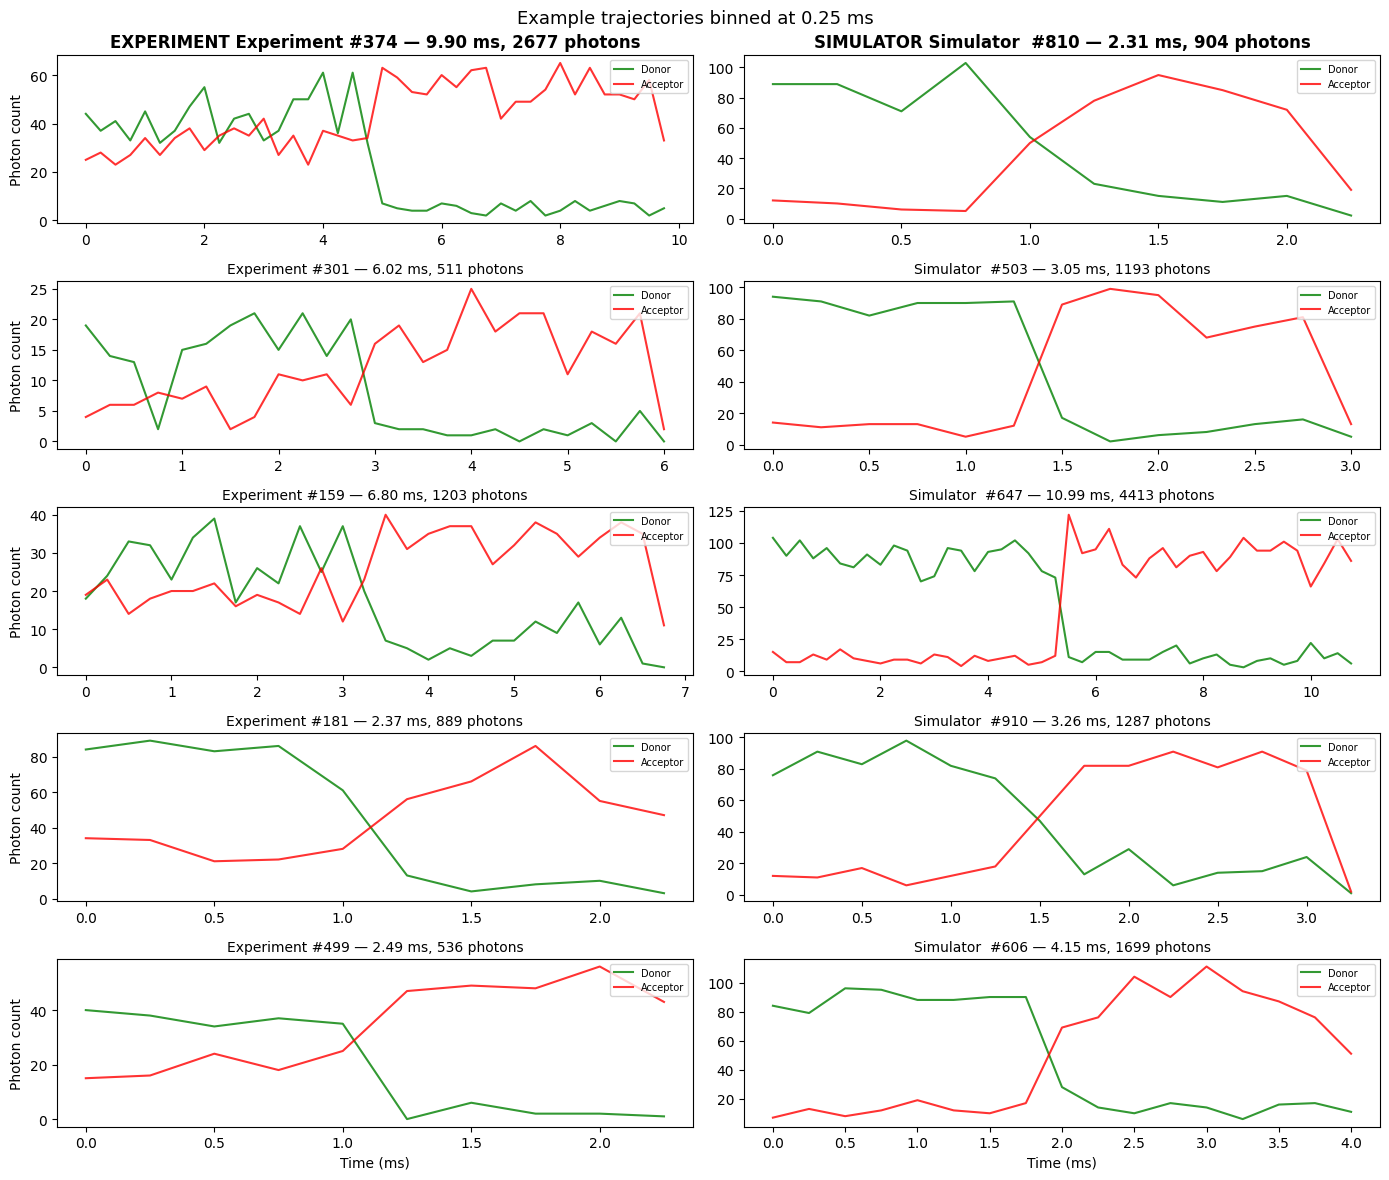

In [71]:
N_SHOW = 5
rng = np.random.default_rng(0)
exp_idx = rng.choice(len(exp_events), N_SHOW, replace=False)
sim_idx = rng.choice(len(sim_events), N_SHOW, replace=False)

fig, axes = plt.subplots(N_SHOW, 2, figsize=(14, 2.4 * N_SHOW))
for row in range(N_SHOW):
    # Experiment (left)
    ipt_e, ch_e = exp_events[exp_idx[row]]
    trace_e = bin_to_counts(ipt_e, ch_e, BIN_WIDTH_MS)
    t_e = np.arange(len(trace_e)) * BIN_WIDTH_MS
    axes[row, 0].plot(t_e, trace_e[:, 0], color="green", alpha=0.8, label="Donor")
    axes[row, 0].plot(t_e, trace_e[:, 1], color="red",   alpha=0.8, label="Acceptor")
    axes[row, 0].set_ylabel("Photon count")
    axes[row, 0].set_title(f"Experiment #{exp_idx[row]} — {ipt_e.sum():.2f} ms, {ipt_e.size} photons", fontsize=10)
    axes[row, 0].legend(fontsize=7, loc="upper right")

    # Simulator (right)
    ipt_s, ch_s = sim_events[sim_idx[row]]
    trace_s = bin_to_counts(ipt_s, ch_s, BIN_WIDTH_MS)
    t_s = np.arange(len(trace_s)) * BIN_WIDTH_MS
    axes[row, 1].plot(t_s, trace_s[:, 0], color="green", alpha=0.8, label="Donor")
    axes[row, 1].plot(t_s, trace_s[:, 1], color="red",   alpha=0.8, label="Acceptor")
    axes[row, 1].set_title(f"Simulator  #{sim_idx[row]} — {ipt_s.sum():.2f} ms, {ipt_s.size} photons", fontsize=10)
    axes[row, 1].legend(fontsize=7, loc="upper right")

axes[-1, 0].set_xlabel("Time (ms)")
axes[-1, 1].set_xlabel("Time (ms)")
axes[0, 0].set_title("EXPERIMENT " + axes[0, 0].get_title(), fontweight="bold")
axes[0, 1].set_title("SIMULATOR " + axes[0, 1].get_title(), fontweight="bold")
plt.suptitle(f"Example trajectories binned at {BIN_WIDTH_MS} ms", fontsize=13)
plt.tight_layout()
plt.show()